# 04 · Model Training — classic ML models
Same cleaned features as notebook 03, but only **classic, easy-to-explain models**:
Linear Regression → Ridge → Lasso → Decision Tree → Random Forest → SVM (SVR) → KNN, then a simple **average** of the best three.

> 📝 **Why not Logistic Regression?** Logistic regression predicts a *class* (yes/no). Our target, SalePrice, is a *number*, so this is a **regression** problem. I show logistic regression in the **bonus section** at the end by turning the problem into "is this house above the median price?".

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

X = pd.read_csv('../data/processed/X_train.csv')
y = pd.read_csv('../data/processed/y.csv').squeeze()           # log(SalePrice)
X_test = pd.read_csv('../data/processed/X_test.csv'); ids = X_test.pop('Id')
print(X.shape, X_test.shape)

(1458, 221) (1459, 221)


## How we judge a model
- **Metric: RMSE on log(price)** — the Kaggle metric. Lower = better. (0.12 ≈ typically ~12% off.)
- **5-fold cross-validation:** split the data in 5 parts; train on 4, predict the 5th, repeat. Every house gets predicted by a model that *never saw it* → an honest score.

In [2]:
kf = KFold(5, shuffle=True, random_state=42)
rmse = lambda p: np.sqrt(np.mean((p - y.values) ** 2))
oof, results = {}, {}          # out-of-fold predictions and scores

def evaluate(name, model):
    oof[name] = cross_val_predict(model, X, y, cv=kf, n_jobs=-1)
    results[name] = rmse(oof[name])
    print(f'{name:18s} CV RMSE = {results[name]:.4f}')

## 1️⃣ Linear Regression  *(baseline)*
**Idea:** price = w₁·feature₁ + w₂·feature₂ + … + b. It finds the weights that make the predictions closest to the real prices.
**Catch:** we have 221 features, many related (e.g. TotalSF, GrLivArea…). With so many, plain linear regression can *overfit* — weights become huge and unstable.

In [3]:
evaluate('Linear Regression', make_pipeline(RobustScaler(), LinearRegression()))

Linear Regression  CV RMSE = 0.1270


## 2️⃣ Ridge Regression  *(linear regression + a penalty)*
**Idea:** same line, but we **punish big weights** (penalty = α × sum of squared weights). Weights shrink → the model is calmer and generalises better.
α is the "strength" of the punishment: too small = no effect, too large = underfit.

In [4]:
evaluate('Ridge', make_pipeline(RobustScaler(), Ridge(alpha=15)))

Ridge              CV RMSE = 0.1144


## 3️⃣ Lasso Regression  *(penalty that can delete features)*
**Idea:** like Ridge but the penalty uses the **absolute** value of weights. This pushes useless features' weights to *exactly zero* → built-in **feature selection**.

Lasso              CV RMSE = 0.1139

Lasso kept 97 of 221 features (the rest got weight 0)


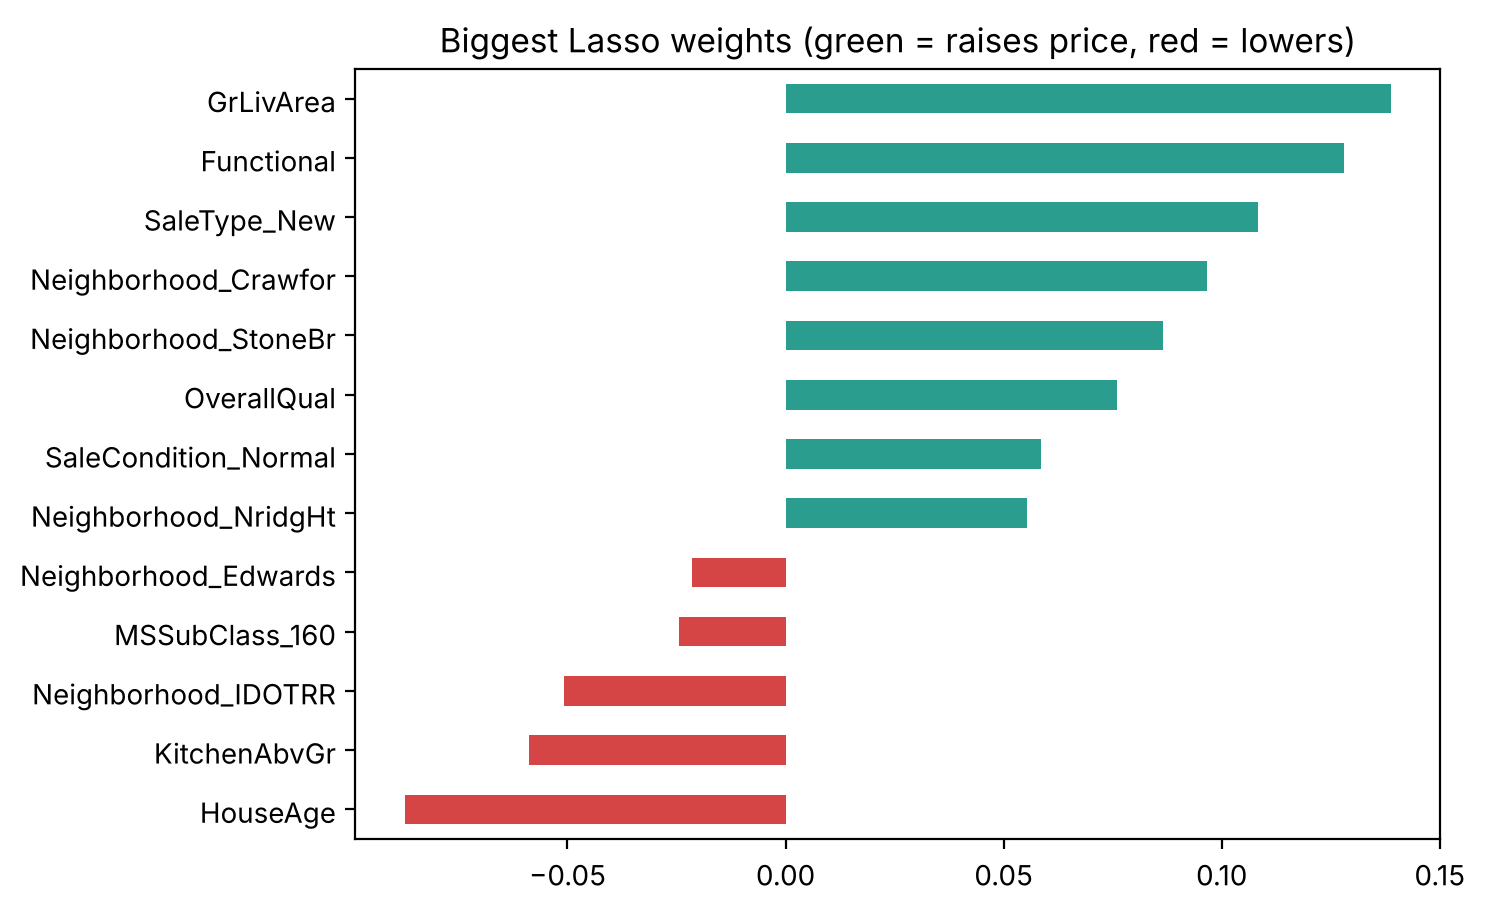

In [5]:
lasso = make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000))
evaluate('Lasso', lasso)
lasso.fit(X, y); coef = pd.Series(lasso[-1].coef_, index=X.columns)
print(f'\nLasso kept {(coef!=0).sum()} of {len(coef)} features (the rest got weight 0)')
top = pd.concat([coef.nlargest(8), coef.nsmallest(5)]).sort_values()
top.plot.barh(figsize=(7,5), color=['#d64545' if v<0 else '#2a9d8f' for v in top], title='Biggest Lasso weights (green = raises price, red = lowers)'); plt.show()

## 4️⃣ Decision Tree
**Idea:** a flowchart of yes/no questions ("Is OverallQual ≤ 6.5?" → "Is TotalSF ≤ 2,000?" …). Each house ends in a leaf; the prediction is the average price of training houses in that leaf.
**Catch:** one tree is unstable — a small change in data changes the whole tree. Deep trees memorise; shallow trees are too simple.

Decision Tree      CV RMSE = 0.1743


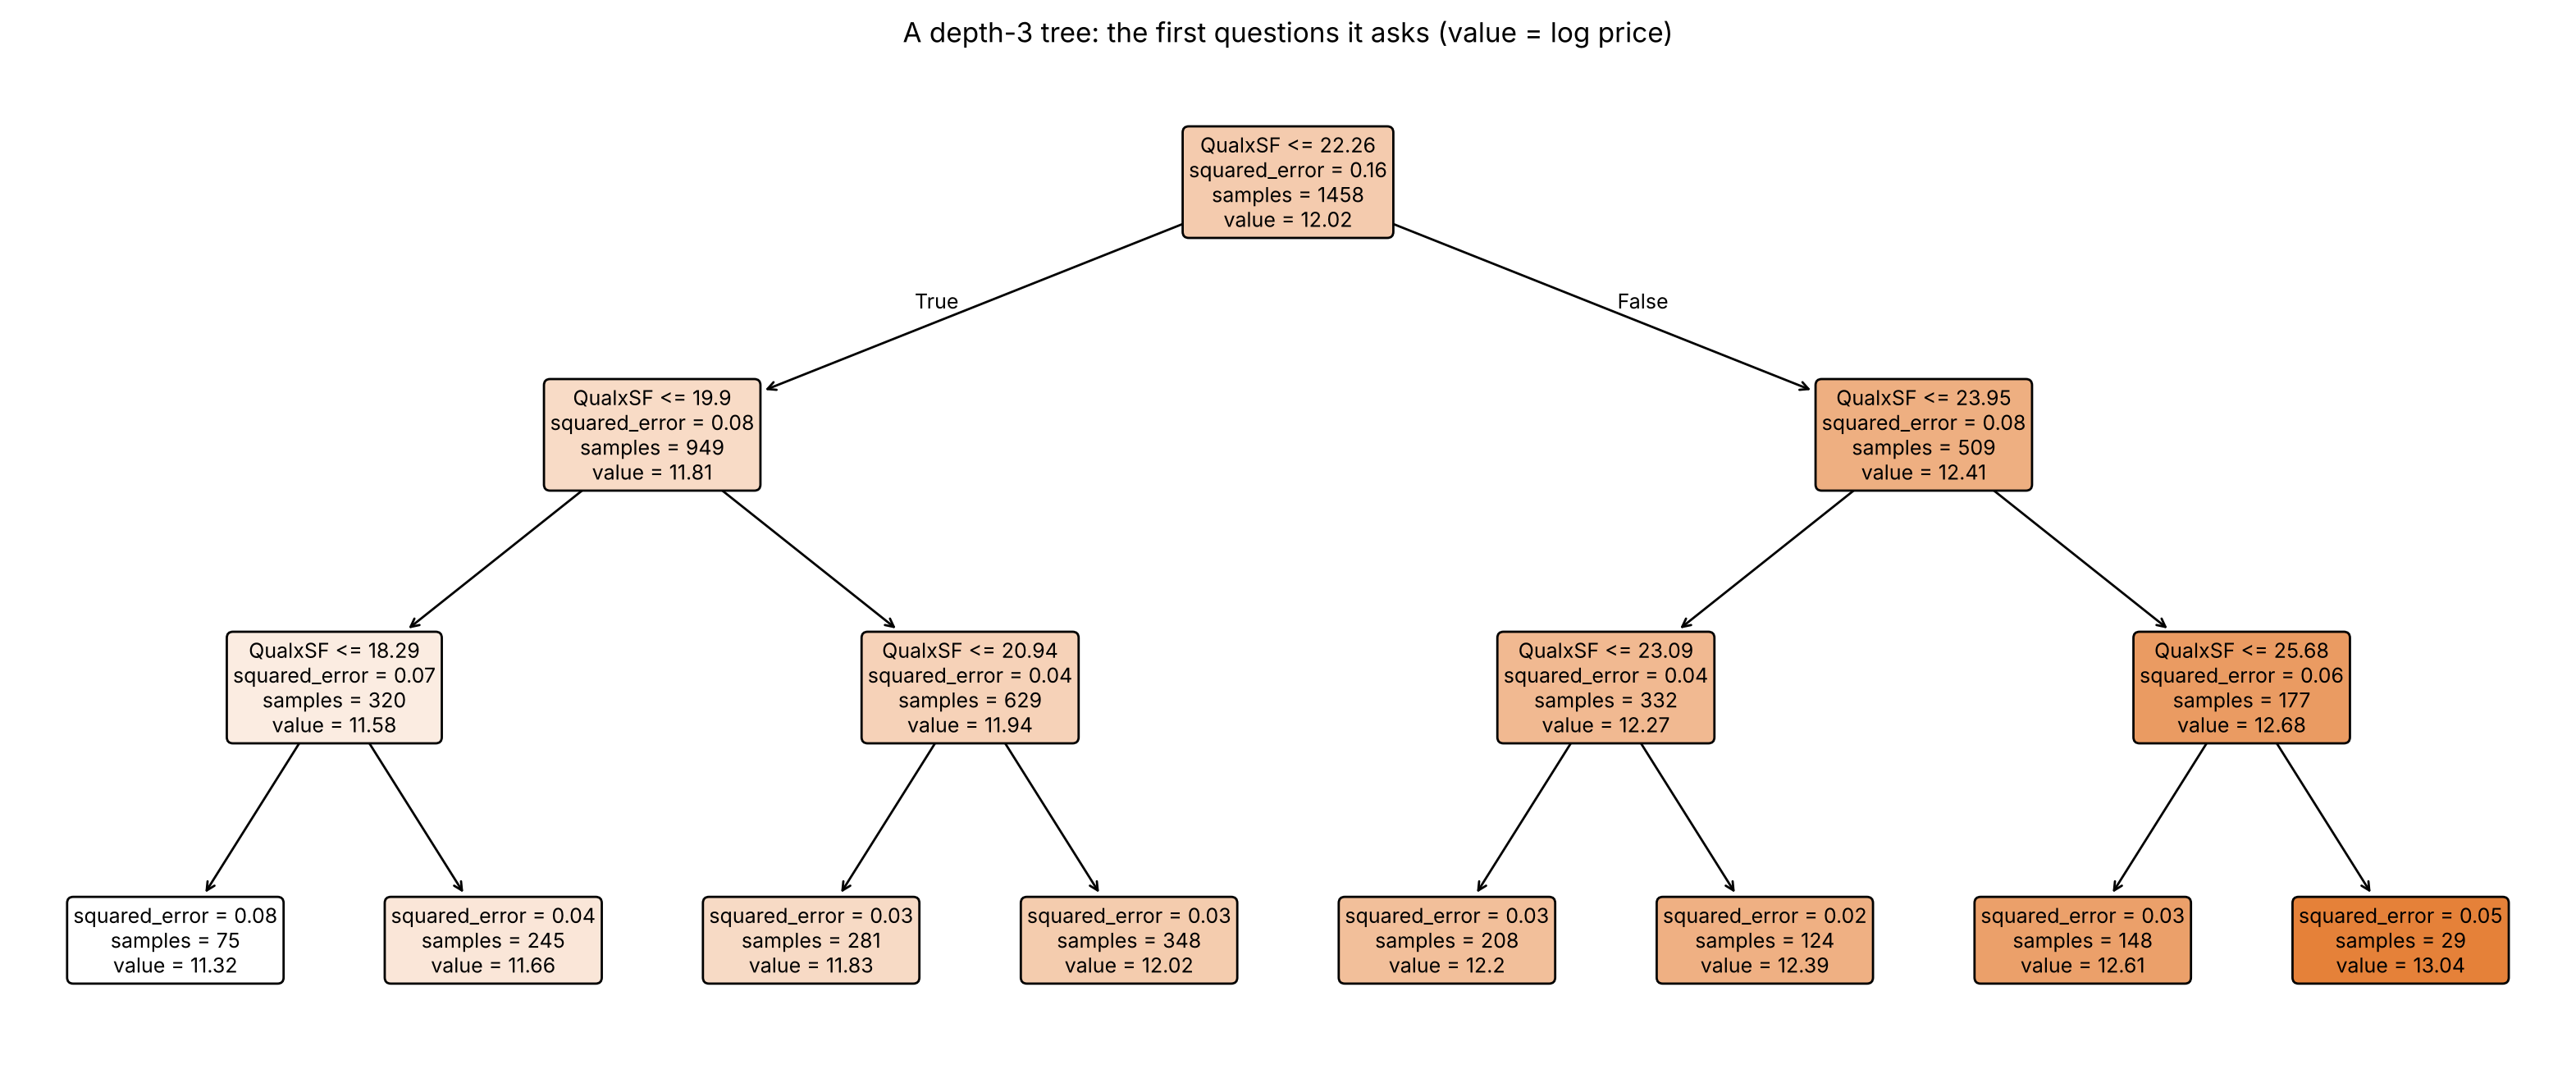

In [6]:
evaluate('Decision Tree', DecisionTreeRegressor(max_depth=6, min_samples_leaf=5, random_state=42))
small = DecisionTreeRegressor(max_depth=3, min_samples_leaf=20, random_state=42).fit(X, y)
plt.figure(figsize=(20,8)); plot_tree(small, feature_names=X.columns, filled=True, rounded=True, fontsize=9, precision=2)
plt.title('A depth-3 tree: the first questions it asks (value = log price)'); plt.show()

## 5️⃣ Random Forest
**Idea:** grow **hundreds of different decision trees**, each on a random sample of houses and a random subset of features, then **average** their predictions ("wisdom of the crowd").
Averaging cancels each tree's mistakes → much better than a single tree.

Random Forest      CV RMSE = 0.1273


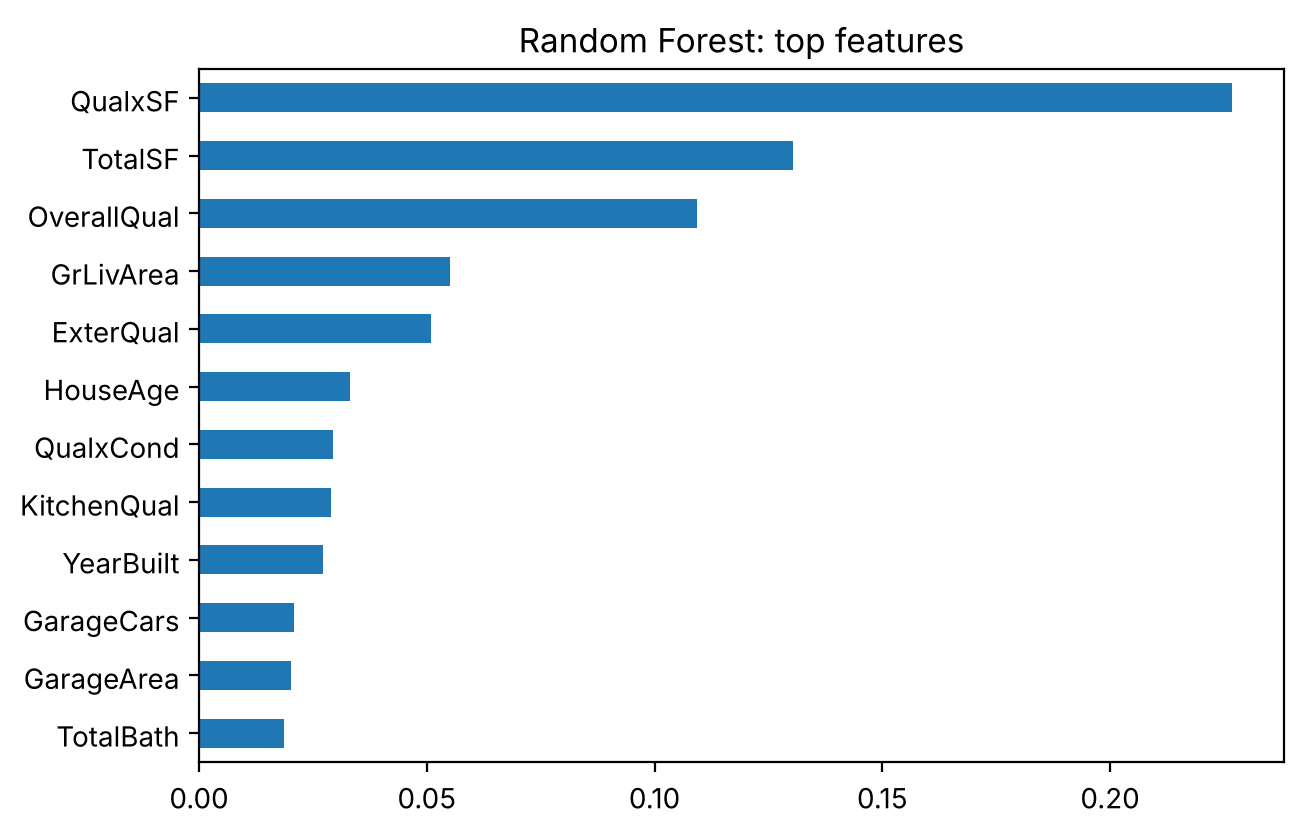

In [7]:
rf = RandomForestRegressor(n_estimators=300, max_features=0.2, min_samples_leaf=1, random_state=42, n_jobs=-1)
evaluate('Random Forest', rf)
rf.fit(X, y)
pd.Series(rf.feature_importances_, index=X.columns).nlargest(12).sort_values().plot.barh(figsize=(7,4.5), title='Random Forest: top features'); plt.show()

## 6️⃣ Support Vector Machine for regression (SVR)
**Idea:** fit a function with a **tube** of width ε around it: points inside the tube cost nothing; only points outside the tube are penalised. With the **RBF kernel** it can draw curved (non-linear) relationships.
- **C** = how strictly we punish points outside the tube. **gamma** = how far one house's influence reaches.
- SVMs are distance-based, so features **must be scaled** (we use StandardScaler).

In [8]:
evaluate('SVR (RBF)', make_pipeline(StandardScaler(), SVR(C=3, epsilon=0.02, gamma=0.0003)))

SVR (RBF)          CV RMSE = 0.1173


## 7️⃣ K-Nearest Neighbours (KNN)
**Idea:** to price a house, find the **k most similar houses** and average their prices. No training, just remembering.
**Catch:** with 221 features, "similar" becomes meaningless (the *curse of dimensionality*) → weak here.

In [9]:
evaluate('KNN (k=5)', make_pipeline(RobustScaler(), KNeighborsRegressor(n_neighbors=5, weights='distance')))

KNN (k=5)          CV RMSE = 0.1743


## 📊 Comparison

Lasso                0.1139
Ridge                0.1144
SVR (RBF)            0.1173
Linear Regression    0.1270
Random Forest        0.1273
KNN (k=5)            0.1743
Decision Tree        0.1743


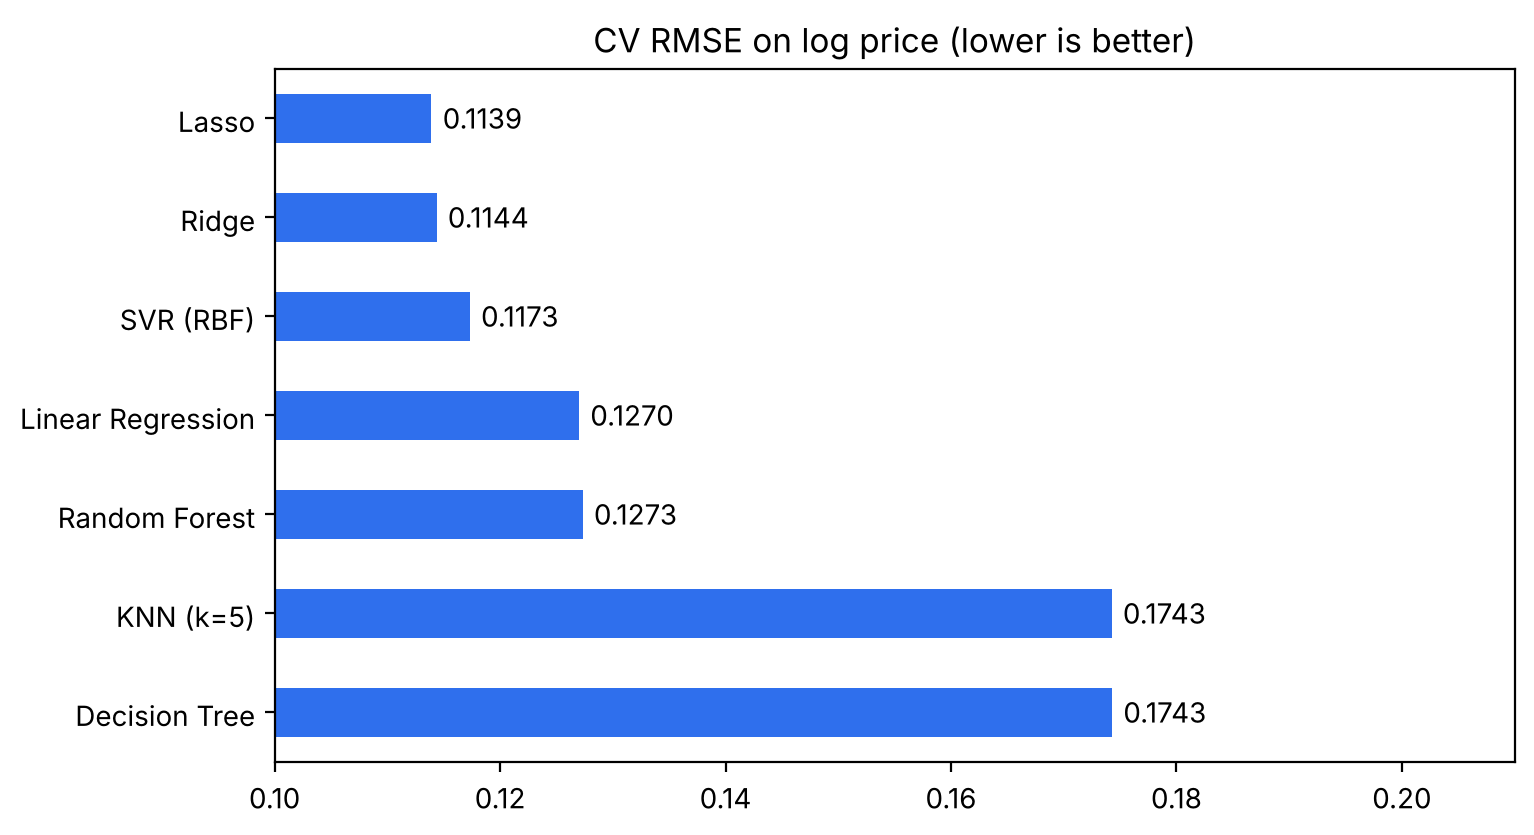

In [10]:
res = pd.Series(results).sort_values()
print(res.round(4).to_string())
res.sort_values(ascending=False).plot.barh(figsize=(8,4.5), color='#2f6fed', title='CV RMSE on log price (lower is better)')
for i,v in enumerate(res.sort_values(ascending=False)): plt.text(v+0.001, i, f'{v:.4f}', va='center')
plt.xlim(0.10, 0.21); plt.show()

**What this tells us**
- 🥇 The **linear family (Ridge / Lasso)** is best — after feature engineering, the price relationship is mostly linear. Plain Linear Regression is worse only because it overfits; the penalty fixes it.
- 🌲 A single **Decision Tree** is weak, but a **Random Forest** (many trees) is much better → averaging helps.
- 📐 **SVR** is strong once scaled and tuned. **KNN** struggles with many features.

## 🤝 Final model: simple average of the 3 best *different* models
Lasso (linear) + SVR (kernel) + Random Forest (trees) make different kinds of mistakes, so averaging them helps. No complicated weights — just `(a + b + c) / 3`.

Average of Lasso + SVR + Random Forest → CV RMSE = 0.1123


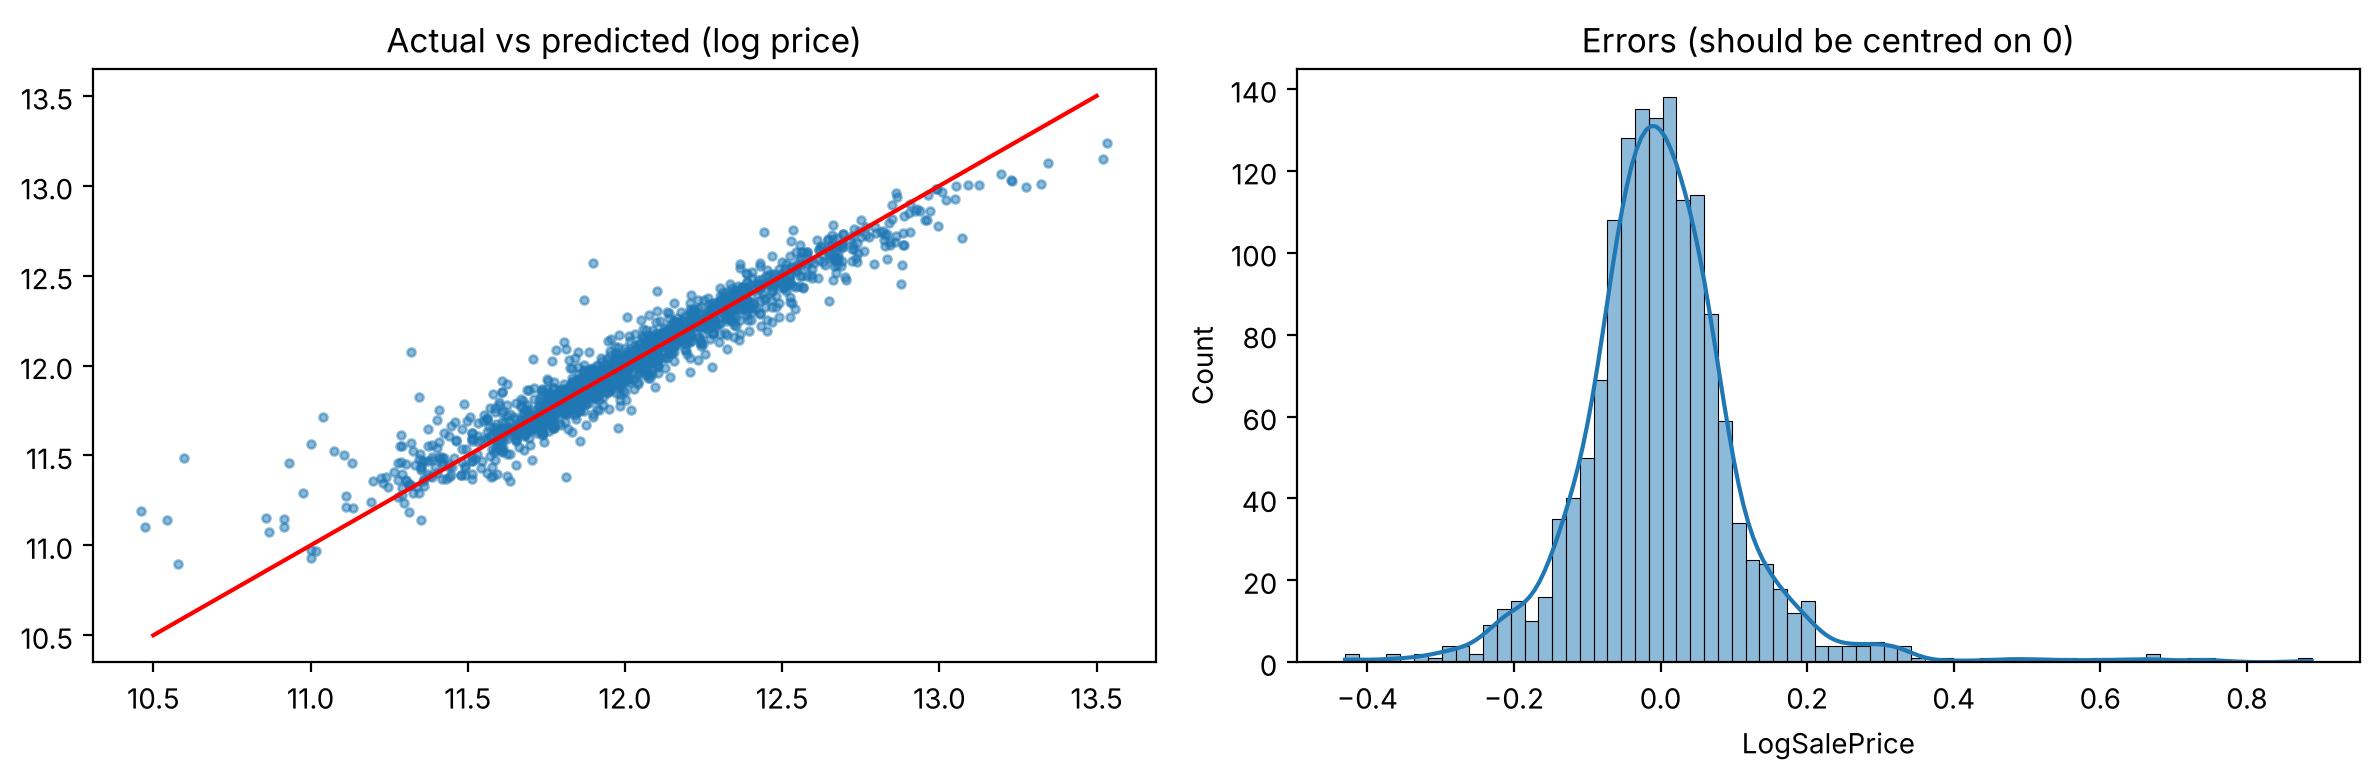

In [11]:
final_oof = (oof['Lasso'] + oof['SVR (RBF)'] + oof['Random Forest']) / 3
print(f'Average of Lasso + SVR + Random Forest → CV RMSE = {rmse(final_oof):.4f}')
fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].scatter(y, final_oof, s=8, alpha=.5); ax[0].plot([10.5,13.5],[10.5,13.5],'r'); ax[0].set_title('Actual vs predicted (log price)')
sns.histplot(final_oof - y, kde=True, ax=ax[1]); ax[1].set_title('Errors (should be centred on 0)'); plt.tight_layout(); plt.show()

In [12]:
# Train the 3 models on ALL data, predict the test set, average, convert log-price back to dollars
final_models = [lasso, make_pipeline(StandardScaler(), SVR(C=3, epsilon=0.02, gamma=0.0003)), rf]
preds = np.mean([m.fit(X, y).predict(X_test) for m in final_models], axis=0)
sub = pd.DataFrame({'Id': ids, 'SalePrice': np.expm1(preds)})
sub.to_csv('../submission_simple.csv', index=False)
print(sub.shape); sub.head()

(1459, 2)


,Id,SalePrice
0,1461,120079.826127
1,1462,161269.058116
2,1463,180889.323307
3,1464,195806.094813
4,1465,196619.617341


## 🎁 Bonus — Logistic Regression & classifiers
Turn the problem into **classification**: *is the house more expensive than the median price?* (yes = 1, no = 0).
Now Logistic Regression, SVM (SVC), Decision Tree, KNN and Random Forest classifiers all apply. (Not used for the Kaggle submission — just to show these models.)

**Logistic regression idea:** like linear regression, but the output is squeezed through an S-shaped curve (sigmoid) into a **probability** between 0 and 1. Above 0.5 → "expensive".

Logistic Regression    0.930
Random Forest          0.925
SVM (SVC)              0.914
Decision Tree          0.896
KNN                    0.894


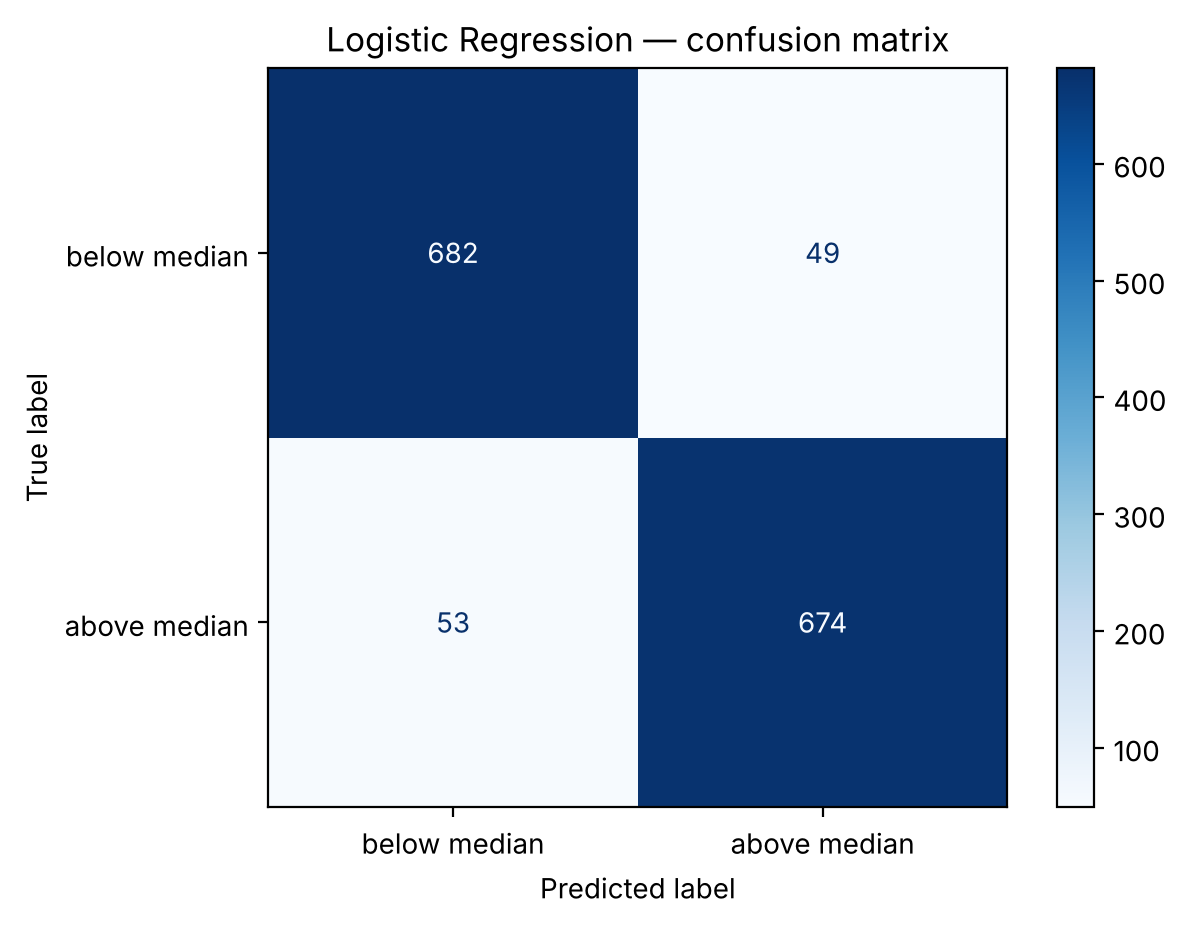

              precision    recall  f1-score   support

below median       0.93      0.93      0.93       731
above median       0.93      0.93      0.93       727

    accuracy                           0.93      1458
   macro avg       0.93      0.93      0.93      1458
weighted avg       0.93      0.93      0.93      1458



In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

yc = (y > y.median()).astype(int)              # 1 = above median price
skf = StratifiedKFold(5, shuffle=True, random_state=42)
clfs = {'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=2000)),
        'SVM (SVC)': make_pipeline(StandardScaler(), SVC(C=1, gamma='scale')),
        'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
        'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=11)),
        'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)}
acc = {k: cross_val_score(m, X, yc, cv=skf, scoring='accuracy', n_jobs=-1).mean() for k, m in clfs.items()}
print(pd.Series(acc).sort_values(ascending=False).round(3).to_string())
pred = cross_val_predict(clfs['Logistic Regression'], X, yc, cv=skf)
ConfusionMatrixDisplay.from_predictions(yc, pred, display_labels=['below median','above median'], cmap='Blues'); plt.title('Logistic Regression — confusion matrix'); plt.show()
print(classification_report(yc, pred, target_names=['below median','above median']))